# Graph Neural Networks from Scratch — Tutorial 9: GNNs for Mesh-Based Systems

### From computational meshes to graphs: learning a heat-conduction surrogate that transfers to new meshes

*📺 Video on YouTube | 🐍 Python · NumPy · SciPy · PyTorch · PyTorch Geometric | Intermediate–Advanced*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

In Tutorials 1–3, we learned how graphs are represented and built a **GCN** from scratch.

In Tutorial 4, we moved to **PyTorch Geometric (PyG)** and the Cora dataset. In Tutorial 5, we opened the layer into **message, aggregate, and update**, and in Exercise 7 we sent the *difference* $\mathbf h_j-\mathbf h_i$ as a message. In Tutorial 6, we learned neighbour weights with **attention**. In Tutorial 7, we compared aggregators and tested GraphSAGE on **unseen nodes**. In Tutorial 8, we added a **readout** for graph-level prediction and saw why sum and mean readouts suit extensive and intensive quantities.

Throughout the series, every "mesh" section ended with the same warning: a GNN is not automatically a numerical method. Now we take the step ourselves.

A computational mesh already **is** a graph: vertices or cells connected by edges and faces. In this tutorial we will:

1. Turn a triangular mesh into a PyG graph.
2. Add **geometric edge features** — the information a mesh has and Cora did not.
3. Generate training data with a small **finite-element heat-conduction solver** — it plays the role that OpenFOAM or another solver would play in practice.
4. Train an **encode–process–decode** GNN to predict the temperature field.
5. Test it on **meshes it has never seen**, including a **finer resolution** than any in training.
6. Check the predictions **physically**: boundary conditions and the residual of the discretised PDE.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | PyG, real-world graph data, practical GCN implementation | ✅ |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | ✅ |
| 6 | Graph Attention Networks (GAT) | learned attention, neighbour weighting, multi-head attention | ✅ |
| 7 | GraphSAGE and Advanced Aggregation | aggregators, neighbour sampling, mini-batches, inductive learning | ✅ |
| 8 | Graph-Level Learning | readout, graph batching, graph classification and regression | ✅ |
| **9** | **GNNs for Mesh-Based Systems** | **mesh → graph, edge features, FEM data, mesh generalisation** | **📍 You are here** |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to progress from understanding graph representations and implementing GNNs from scratch to using practical tools for learning from complex connected systems, including computational meshes and physical systems.

---

In this tutorial, we will explore the essential components of mesh-based graph learning:

- How mesh vertices, cells, and faces map to graph nodes and edges.
- Converting triangular elements into `edge_index` — from scratch and with PyG's `FaceToEdge`.
- Node features (coordinates, boundary flag, heat source) and edge features (relative position, distance).
- A minimal **P1 finite-element solver** for steady heat conduction, verified against an exact solution.
- A dataset of simulations on **different meshes and resolutions**, split **by simulation case**.
- An **edge-aware message-passing** network in the encode–process–decode style of MeshGraphNets.
- A fair comparison: **MLP** (no connectivity) vs. **GNN without edge features** vs. **edge-aware GNN**.
- Physical checks: boundary-condition error and **PDE residual**.
- Receptive field vs. mesh resolution — why a GNN trained on coarse meshes can struggle on fine ones.

## The learning process

Our workflow in this tutorial will follow this sequence:

```text
        Triangular Mesh
                |
                v
   Mesh → Graph (edge_index, edge_attr)
                |
                v
   FEM Solver → Temperature Fields   (training data)
                |
                v
   Dataset of Simulations on Many Meshes
                |
                v
   Encoder → Message Passing × L → Decoder
                |
                v
   Train → Validate on Held-Out Simulations
                |
                v
   Test on Unseen Meshes + Finer Resolution
                |
                v
   Physical Checks: BCs + PDE Residual
```

The GNN pieces are the ones from Tutorials 5–8: a `MessagePassing` layer, mini-batches of graphs, and a node-level output. What is new is where the graphs come from — a mesh and a solver — and how strictly we evaluate them.

> **Is this a CFD solver?** No. It is a learned **surrogate**: a model that imitates a solver's output much faster once trained. We use steady heat conduction because it is simple to solve exactly, but the workflow — mesh to graph, solver data, split by case, physical checks — is the same one you would use with OpenFOAM data.
>
> Pay particular attention to Part VII. A model that scores well on held-out *nodes* of a training mesh can still fail on a *new* mesh. Testing on unseen meshes and resolutions is what makes a mesh surrogate trustworthy.

**Let's turn meshes into graphs and see how far a message-passing network can go as a physics surrogate.**

## 1. Why represent a mesh as a graph?

A mesh splits a domain into connected elements. Depending on the numerical method, the unknowns live in different places:

| Numerical method | Unknowns stored at | Natural graph |
|---|---|---|
| Finite elements (P1) | mesh **vertices** | vertex graph: vertices connected by element edges |
| Finite volumes | **cell centres** | cell graph: cells connected through shared faces |
| Staggered / face-based schemes | **faces** | face graph, or edge features on the cell graph |

In this tutorial we use a **vertex graph**, because our solver is a P1 finite-element method that stores temperature at the vertices.

| Mesh concept | Graph representation |
|---|---|
| Vertex (or cell centre) | node |
| Element edge (or shared face) | edge, in both directions |
| Coordinates | node feature or `pos` |
| Temperature, pressure, velocity | node features or targets |
| Relative position, distance | edge features |
| Face area, face normal | edge features (finite volumes) |
| Boundary marker | node feature |

A GNN layer is **local**, like a numerical stencil: each node updates from its direct neighbours. Unlike a fixed stencil, the update rule is **learned**, and it works on any mesh topology — the reason GraphSAGE's inductive property (Tutorial 7) matters so much here.

## 2. Setup

We use the same environment as Tutorials 4–8, plus SciPy for the finite-element solver. If PyG is missing, the cell below installs it.

In [1]:
import sys
import subprocess

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)

try:
    import torch_geometric
except ImportError:
    print("PyTorch Geometric is not installed. Installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"])
    import torch_geometric
    print("Installation complete.")

import scipy
print("PyG:", torch_geometric.__version__)
print("SciPy:", scipy.__version__)

torch.manual_seed(7)
np.random.seed(7)

PyTorch: 2.11.0+cu130


/home/rohit/venvs/py13env/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyG: 2.8.1
SciPy: 1.17.1


In [2]:
# Training configuration. On a CPU, each GNN takes about 5 minutes to train;
# on a GPU it is much faster. Reduce EPOCHS for a quick run.
NUM_LAYERS = 8   # message-passing layers in the processor
EPOCHS = 100       # training epochs per model

# Part I — From mesh to graph

## 3. A triangular mesh

We build a mesh of the unit square:

1. Place an $n\times n$ grid of points.
2. Move every **interior** point by a small random amount, so the mesh is irregular. Boundary points stay on the boundary.
3. Triangulate the points (Delaunay triangulation).

Each call with a different `seed` gives a different mesh with the same resolution — exactly what we need later to test on **unseen meshes**.

In [3]:
from matplotlib.tri import Triangulation

def make_mesh(n, jitter=0.25, seed=0):
    """Irregular triangular mesh of the unit square with about n x n vertices.

    Returns points [N, 2], triangles [num_triangles, 3], and a boundary mask [N].
    """
    rng = np.random.default_rng(seed)
    grid = np.linspace(0.0, 1.0, n)
    X, Y = np.meshgrid(grid, grid)
    points = np.column_stack([X.ravel(), Y.ravel()])

    boundary = (np.isclose(points, 0.0) | np.isclose(points, 1.0)).any(axis=1)
    h = 1.0 / (n - 1)
    points[~boundary] += rng.uniform(-jitter * h, jitter * h, size=(int((~boundary).sum()), 2))

    triangles = Triangulation(points[:, 0], points[:, 1]).triangles
    return points, triangles, boundary

points, triangles, boundary = make_mesh(n=14, seed=0)

print("Vertices:", len(points))
print("Triangles:", len(triangles))
print("Boundary vertices:", int(boundary.sum()))

Vertices: 196
Triangles: 338
Boundary vertices: 52


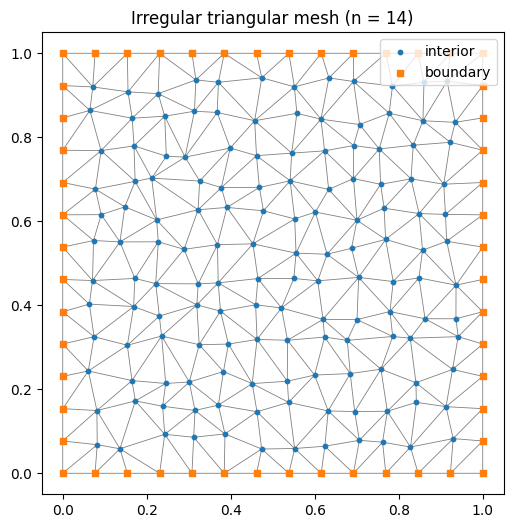

In [4]:
plt.figure(figsize=(6, 6))
plt.triplot(points[:, 0], points[:, 1], triangles, linewidth=0.6, color="gray")
plt.scatter(points[~boundary, 0], points[~boundary, 1], s=10, label="interior")
plt.scatter(points[boundary, 0], points[boundary, 1], s=14, marker="s", label="boundary")
plt.title("Irregular triangular mesh (n = 14)")
plt.gca().set_aspect("equal")
plt.legend(loc="upper right")
plt.show()

## 4. Triangles to `edge_index`

Each triangle $(i, j, k)$ contributes three undirected edges: $(i,j)$, $(j,k)$, $(k,i)$. Neighbouring triangles share edges, so we must remove duplicates. Then, as always in this series, we store both directions.

```text
triangles               all triangle edges        unique, sorted          both directions
[0, 1, 5]   ──▶   (0,1) (1,5) (5,0)  ...   ──▶   (0,1) (0,5) ...   ──▶   0→1 1→0 0→5 5→0 ...
[1, 6, 5]         (1,6) (6,5) (5,1)  ...
```

The draft version of this function used a Python `set` and a loop. A vectorised version with NumPy is shorter and much faster on large meshes:

In [5]:
def triangles_to_edge_index(triangles):
    """Unique undirected mesh edges, stored in both directions. Shape [2, 2 * num_edges]."""
    pairs = np.concatenate([triangles[:, [0, 1]], triangles[:, [1, 2]], triangles[:, [2, 0]]])
    pairs = np.unique(np.sort(pairs, axis=1), axis=0)          # remove duplicates
    both = np.concatenate([pairs, pairs[:, ::-1]])              # i->j and j->i
    return torch.tensor(both.T, dtype=torch.long)

edge_index = triangles_to_edge_index(triangles)

print("edge_index shape:", tuple(edge_index.shape))
print("Undirected mesh edges:", edge_index.size(1) // 2)

# Euler's formula for a triangulated disc: V - E + F = 1
V, E, Fc = len(points), edge_index.size(1) // 2, len(triangles)
print(f"Euler check V - E + F = {V} - {E} + {Fc} = {V - E + Fc}")

edge_index shape: (2, 1066)
Undirected mesh edges: 533
Euler check V - E + F = 196 - 533 + 338 = 1


Euler's formula for a planar mesh without holes, $V-E+F=1$, gives a quick sanity check that no edges are missing or duplicated.

## 5. Verify against PyG's `FaceToEdge`

PyG stores triangles in a `face` tensor of shape `[3, num_triangles]` and provides a transform, `FaceToEdge`, that does the same conversion. As in every tutorial, we check our version against the library.

In [6]:
from torch_geometric.data import Data
import torch_geometric.transforms as T

mesh_data = Data(pos=torch.tensor(points, dtype=torch.float),
                 face=torch.tensor(triangles.T, dtype=torch.long))
mesh_data = T.FaceToEdge(remove_faces=False)(mesh_data)

ours = set(map(tuple, edge_index.t().tolist()))
pyg = set(map(tuple, mesh_data.edge_index.t().tolist()))
print("PyG edges:", len(pyg), "| our edges:", len(ours))
print("Identical edge sets:", ours == pyg)

PyG edges: 1066 | our edges: 1066
Identical edge sets: True


## 6. What does the graph look like?

On a structured triangular grid, every interior vertex has exactly 6 neighbours. Our jittered Delaunay mesh is irregular, so degrees vary — just like a real unstructured mesh.

Degree: min = 2, mean = 5.44, max = 8
Interior mean degree: 6.01


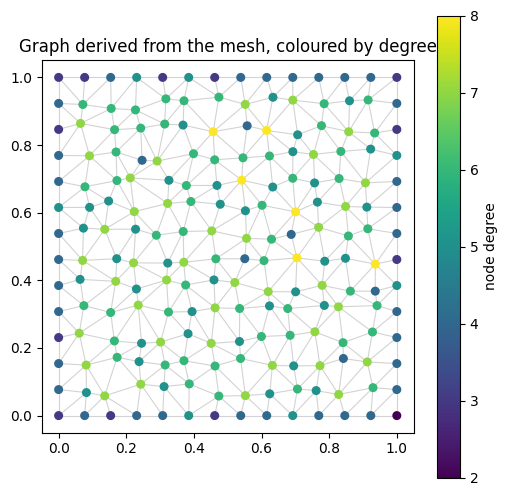

In [7]:
from torch_geometric.utils import degree

deg = degree(edge_index[1], num_nodes=len(points))
print(f"Degree: min = {int(deg.min())}, mean = {deg.mean():.2f}, max = {int(deg.max())}")
print("Interior mean degree:", round(deg[torch.tensor(~boundary)].mean().item(), 2))

plt.figure(figsize=(6, 6))
for i, j in edge_index.t().tolist():
    if i < j:
        plt.plot(*zip(points[i], points[j]), color="lightgray", linewidth=0.8, zorder=1)
sc = plt.scatter(points[:, 0], points[:, 1], c=deg.numpy(), s=30, cmap="viridis", zorder=2)
plt.colorbar(sc, label="node degree")
plt.title("Graph derived from the mesh, coloured by degree")
plt.gca().set_aspect("equal")
plt.show()

## 🧪 Hands-on Exercise 1

1. Build meshes with `n = 8, 14, 28`. How do the numbers of nodes and edges grow? Does the mean interior degree change?
2. Set `jitter=0.0`. What is the degree distribution now?
3. A **finite-volume cell graph** connects two triangles if they share an edge. Write a function that builds this graph from `triangles`. (Hint: map each sorted edge to the list of triangles that contain it.)

In [8]:
# TODO: explore mesh resolution, jitter, and the cell (dual) graph.

# for n in [8, 14, 28]:
#     p, t, b = make_mesh(n)
#     ei = triangles_to_edge_index(t)
#     print(n, len(p), ei.size(1) // 2)

# Part II — The physical problem and a finite-element solver

## 7. Steady heat conduction

We solve the steady heat equation on the unit square $\Omega$ with a heat source $f$ and fixed zero temperature on the boundary:

$$
-\nabla^2 T = f\quad\text{in }\Omega,\qquad T=0\quad\text{on }\partial\Omega
$$

Think of a thin metal plate with heaters on it and its edges held in an ice bath. The temperature at one point depends on the heat sources **everywhere** in the plate — this is a **global** problem, which will matter when we look at the GNN's receptive field.

## 8. A minimal P1 finite-element solver

To train a surrogate, we need simulation data. In practice you would export it from OpenFOAM, Abaqus, or another solver. Here we write the smallest possible solver ourselves, so the notebook is self-contained.

For linear (P1) triangles, the method reduces to a sparse linear system:

$$
\mathbf K\,\mathbf T=\mathbf M\,\mathbf f
$$

| Symbol | Meaning |
|---|---|
| $\mathbf K$ | stiffness matrix — the discrete $-\nabla^2$, built triangle by triangle |
| $\mathbf M$ | lumped mass matrix — diagonal, each vertex gets one third of its triangles' areas |
| $\mathbf f$ | heat source at the vertices |

The stiffness matrix connects vertex $i$ only to the vertices it shares a triangle with — **exactly the edges of our graph**. A finite-element operator is itself a message-passing operation with fixed, geometry-based weights.

In [8]:
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def assemble_fem(points, triangles):
    """P1 stiffness matrix K (sparse) and lumped mass vector m."""
    p = points[triangles]                              # [num_tri, 3, 2]
    x, y = p[..., 0], p[..., 1]
    b = np.stack([y[:, 1] - y[:, 2], y[:, 2] - y[:, 0], y[:, 0] - y[:, 1]], axis=1)
    c = np.stack([x[:, 2] - x[:, 1], x[:, 0] - x[:, 2], x[:, 1] - x[:, 0]], axis=1)
    area = 0.5 * np.abs(b[:, 0] * c[:, 1] - b[:, 1] * c[:, 0])

    # Element stiffness: (b b^T + c c^T) / (4 A)
    K_local = (b[:, :, None] * b[:, None, :] + c[:, :, None] * c[:, None, :]) / (4 * area[:, None, None])
    rows = np.repeat(triangles, 3, axis=1).ravel()
    cols = np.tile(triangles, 3).ravel()
    K = sp.csr_matrix((K_local.ravel(), (rows, cols)), shape=(len(points), len(points)))

    m = np.zeros(len(points))
    np.add.at(m, triangles.ravel(), np.repeat(area / 3, 3))
    return K, m

def solve_heat(K, m, f, boundary):
    """Solve K T = M f with T = 0 on the boundary."""
    T = np.zeros(len(f))
    interior = ~boundary
    T[interior] = spla.spsolve(K[interior][:, interior].tocsc(), (m * f)[interior])
    return T

## 9. Verify the solver against an exact solution

Before trusting any data generator, test it on a problem with a known answer. For

$$
T_{\text{exact}}(x,y)=\sin(\pi x)\sin(\pi y)\quad\Rightarrow\quad f=2\pi^2\sin(\pi x)\sin(\pi y)
$$

the error should shrink by roughly a factor of 4 each time the mesh spacing halves — second-order convergence, as expected for P1 elements. (The jittered meshes make the ratio a little irregular.)

In [9]:
for n in [9, 17, 33]:
    p, t, b = make_mesh(n, seed=1)
    K, m = assemble_fem(p, t)
    f_exact = 2 * np.pi**2 * np.sin(np.pi * p[:, 0]) * np.sin(np.pi * p[:, 1])
    T_num = solve_heat(K, m, f_exact, b)
    T_ref = np.sin(np.pi * p[:, 0]) * np.sin(np.pi * p[:, 1])
    print(f"n = {n:2d} | h = {1 / (n - 1):.4f} | max error = {np.abs(T_num - T_ref).max():.2e}")

n =  9 | h = 0.1250 | max error = 2.86e-02
n = 17 | h = 0.0625 | max error = 9.59e-03
n = 33 | h = 0.0312 | max error = 2.29e-03


## 10. Random heat sources

Each simulation gets a different heat source: one to three Gaussian "heaters" at random positions, with random widths and strengths.

$$
f(\mathbf r)=\sum_{k=1}^{K}a_k\exp\left(-\frac{\lVert\mathbf r-\mathbf c_k\rVert^2}{2w_k^2}\right)
$$

The surrogate must learn the map **heat source → temperature field**, for any source and any mesh.

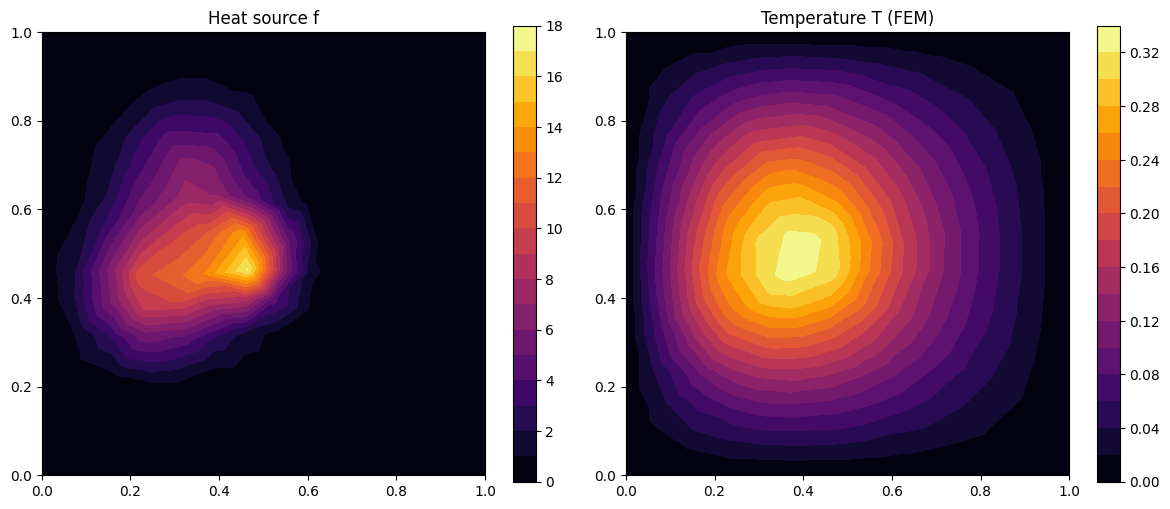

In [10]:
def random_source(points, rng):
    f = np.zeros(len(points))
    for _ in range(rng.integers(1, 4)):
        centre = rng.uniform(0.2, 0.8, size=2)
        width = rng.uniform(0.05, 0.15)
        strength = rng.uniform(5.0, 20.0)
        f += strength * np.exp(-((points - centre) ** 2).sum(axis=1) / (2 * width**2))
    return f

rng = np.random.default_rng(3)
K, m = assemble_fem(points, triangles)
f_demo = random_source(points, rng)
T_demo = solve_heat(K, m, f_demo, boundary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, values, title in zip(axes, [f_demo, T_demo], ["Heat source f", "Temperature T (FEM)"]):
    cf = ax.tricontourf(points[:, 0], points[:, 1], triangles, values, levels=20, cmap="inferno")
    fig.colorbar(cf, ax=ax)
    ax.set_title(title)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

The temperature is a smoothed, spread-out version of the source, and it is zero on the boundary. Notice that heat from one heater raises the temperature far away from it — the global nature of the problem.

## 🧪 Hands-on Exercise 2

The FEM operator $\mathbf K$ is a sparse matrix whose non-zeros sit exactly on the mesh edges.

1. Check this: compare the non-zero pattern of `K` (excluding the diagonal) with `edge_index`.
2. Compute `K @ T_demo` and compare it with `m * f_demo` at interior nodes. What do you expect?

In [12]:
# TODO: compare the sparsity pattern of K with edge_index.

# K_coo = K.tocoo()
# off_diag = K_coo.row != K_coo.col
# fem_pairs = set(zip(K_coo.row[off_diag].tolist(), K_coo.col[off_diag].tolist()))
# print(fem_pairs == set(map(tuple, edge_index.t().tolist())))

# Part III — Node and edge features

## 11. What does the model see?

**Node features** for vertex $i$:

$$
\mathbf x_i=\left[\,x_i,\ y_i,\ b_i,\ f_i\,\right]
$$

- $x_i, y_i$ — coordinates (the domain is fixed, so absolute position is meaningful here)
- $b_i\in\{0,1\}$ — **boundary flag**, so the model can learn that $T=0$ there
- $f_i$ — heat source at the vertex

**Edge features** for the directed edge $j\rightarrow i$:

$$
\mathbf e_{ji}=\left[\,\Delta x_{ji},\ \Delta y_{ji},\ d_{ji}\,\right],\qquad \Delta\mathbf r_{ji}=\mathbf r_j-\mathbf r_i,\quad d_{ji}=\lVert\Delta\mathbf r_{ji}\rVert
$$

These carry the **geometry** of the mesh: direction and distance to each neighbour. On Cora, an edge was just "cites". On a mesh, an edge has a length and an orientation, and the physics depends on both — the Laplacian scales like $1/h^2$, where $h$ is the local spacing.

**Target:** the FEM temperature $T_i$ at every vertex — a node-level regression.

We scale features and targets by fixed constants (10 for the source, edge geometry, and temperature) so they are of order one. Fixed constants, rather than per-dataset statistics, keep the scaling identical on every mesh.

In [11]:
F_SCALE, E_SCALE, T_SCALE = 0.1, 10.0, 10.0

def mesh_to_data(points, triangles, boundary, f, T):
    edge_index = triangles_to_edge_index(triangles)
    src, dst = edge_index
    rel = points[src.numpy()] - points[dst.numpy()]                  # r_j - r_i for edge j -> i
    dist = np.linalg.norm(rel, axis=1, keepdims=True)

    return Data(
        x=torch.tensor(np.column_stack([points, boundary, F_SCALE * f]), dtype=torch.float),
        edge_index=edge_index,
        edge_attr=torch.tensor(E_SCALE * np.column_stack([rel, dist]), dtype=torch.float),
        y=torch.tensor(T_SCALE * T, dtype=torch.float).view(-1, 1),
        pos=torch.tensor(points, dtype=torch.float),
        face=torch.tensor(triangles.T, dtype=torch.long),
        boundary=torch.tensor(boundary),
    )

demo = mesh_to_data(points, triangles, boundary, f_demo, T_demo)
print(demo)
print("\nFirst three nodes [x, y, boundary, f]:\n", demo.x[:3])
print("\nFirst three edges:", demo.edge_index[:, :3].t().tolist())
print("Their features [dx, dy, d]:\n", demo.edge_attr[:3])

Data(x=[196, 4], edge_index=[2, 1066], edge_attr=[1066, 3], y=[196, 1], pos=[196, 2], face=[3, 338], boundary=[196])

First three nodes [x, y, boundary, f]:
 tensor([[0.0000e+00, 0.0000e+00, 1.0000e+00, 3.7862e-06],
        [7.6923e-02, 0.0000e+00, 1.0000e+00, 2.0924e-05],
        [1.5385e-01, 0.0000e+00, 1.0000e+00, 6.5237e-05]])

First three edges: [[0, 1], [0, 14], [0, 15]]
Their features [dx, dy, d]:
 tensor([[-0.7692,  0.0000,  0.7692],
        [ 0.0000, -0.7692,  0.7692],
        [-0.8219, -0.6807,  1.0672]])


Always check that `edge_attr` has **one row per directed edge** — the same number of columns as `edge_index`. Mismatches here are a common silent bug.

# Part IV — A dataset of simulations

## 12. Many meshes, many sources

A surrogate is only useful if it works on **new** simulations. So each sample gets its **own mesh** (a different random seed) and its **own heat source**. We create four groups:

| Split | Mesh resolution $n$ | Purpose |
|---|---|---|
| Train | 12, 16, 20 | learn the mapping |
| Validation | 12, 16, 20 | choose the best checkpoint |
| Test — same resolutions | 12, 16, 20 | new meshes and sources, familiar resolution |
| **Test — finer mesh** | **28** | **a resolution never seen in training** |

The split is **by simulation case**: no mesh or source appears in more than one split. This is the key difference from the node-level splits we used on Cora.

In [12]:
import time

def simulate(n, seed):
    rng = np.random.default_rng(seed)
    p, t, b = make_mesh(n, seed=seed)
    K, m = assemble_fem(p, t)
    f = random_source(p, rng)
    return mesh_to_data(p, t, b, f, solve_heat(K, m, f, b))

start = time.time()
train_set = [simulate(n, seed) for n in (12, 16, 20) for seed in range(1000 * n, 1000 * n + 80)]
val_set   = [simulate(n, seed) for n in (12, 16, 20) for seed in range(1000 * n + 500, 1000 * n + 510)]
test_same = [simulate(n, seed) for n in (12, 16, 20) for seed in range(1000 * n + 700, 1000 * n + 710)]
test_fine = [simulate(28, seed) for seed in range(90000, 90030)]

print(f"Generated {len(train_set) + len(val_set) + len(test_same) + len(test_fine)} simulations "
      f"in {time.time() - start:.1f} s")
for name, ds in [("Train", train_set), ("Validation", val_set), ("Test (same n)", test_same), ("Test (n = 28)", test_fine)]:
    sizes = [d.num_nodes for d in ds]
    print(f"{name:14s}: {len(ds):3d} graphs, {min(sizes)}–{max(sizes)} nodes each")

Generated 330 simulations in 2.8 s
Train         : 240 graphs, 144–400 nodes each
Validation    :  30 graphs, 144–400 nodes each
Test (same n) :  30 graphs, 144–400 nodes each
Test (n = 28) :  30 graphs, 784–784 nodes each


## 13. Mini-batches of meshes

Each simulation is one graph, so we batch them exactly as in Tutorial 8 — PyG's `DataLoader` stacks several meshes into one disconnected graph.

In [13]:
from torch_geometric.loader import DataLoader

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
batch = next(iter(train_loader))
print(batch)
print("Meshes in batch:", batch.num_graphs)

DataBatch(x=[4112, 4], edge_index=[2, 22688], edge_attr=[22688, 3], y=[4112, 1], pos=[4112, 2], face=[3, 7248], boundary=[4112], batch=[4112], ptr=[17])
Meshes in batch: 16


# Part V — An edge-aware message-passing network

## 14. The edge-aware layer

We extend the message function from Tutorial 5 with edge features. For each edge $j\rightarrow i$:

$$
\mathbf m_{j\rightarrow i}=\phi_m\left(\left[\mathbf h_i\ \Vert\ \mathbf h_j\ \Vert\ \mathbf e_{ji}\right]\right)
$$

$$
\mathbf m_i=\operatorname{mean}_{j\in\mathcal N(i)}\mathbf m_{j\rightarrow i}
$$

$$
\mathbf h_i\leftarrow\mathbf h_i+\phi_u\left(\left[\mathbf h_i\ \Vert\ \mathbf m_i\right]\right)
$$

$\phi_m$ and $\phi_u$ are small MLPs. The last line is a **residual update**: each layer adds a correction to $\mathbf h_i$, which makes deep stacks easier to train.

| Step | Tutorial 5 (`PyGMeanSAGEConv`) | This layer |
|---|---|---|
| Message | $\mathbf h_j$ | MLP of $\mathbf h_i$, $\mathbf h_j$, **edge geometry** |
| Aggregate | mean | mean |
| Update | $\mathbf W[\mathbf h_i\Vert\mathbf m_i]$ | MLP, plus residual |

Setting `use_edge_attr=False` gives the same layer without geometry — our ablation.

In [14]:
from torch_geometric.nn import MessagePassing

class EdgeAwareLayer(MessagePassing):
    def __init__(self, hidden_dim, edge_dim, use_edge_attr=True):
        super().__init__(aggr="mean")
        self.use_edge_attr = use_edge_attr
        in_dim = 2 * hidden_dim + (edge_dim if use_edge_attr else 0)
        self.message_mlp = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.ReLU(),
                                         nn.Linear(hidden_dim, hidden_dim), nn.ReLU())
        self.update_mlp = nn.Sequential(nn.Linear(2 * hidden_dim, hidden_dim), nn.ReLU(),
                                        nn.Linear(hidden_dim, hidden_dim))

    def forward(self, h, edge_index, edge_attr):
        m = self.propagate(edge_index, h=h, edge_attr=edge_attr)    # message + aggregate
        return h + self.update_mlp(torch.cat([h, m], dim=-1))       # residual update

    def message(self, h_i, h_j, edge_attr):
        parts = [h_i, h_j, edge_attr] if self.use_edge_attr else [h_i, h_j]
        return self.message_mlp(torch.cat(parts, dim=-1))

## 15. Encode – process – decode

This is the architecture popularised by **MeshGraphNets** (Pfaff et al., 2021), in a compact form:

```text
 node features [x, y, b, f] ──▶ Encoder MLP ──▶ h⁰
                                                  │
                    edge_attr ──▶ EdgeAwareLayer  │  × L   (processor)
                                                  ▼
                                                 h^L ──▶ Decoder MLP ──▶ T̂  (one value per node)
```

- **Encoder:** lifts the 4 raw features to a hidden size $H$.
- **Processor:** $L$ message-passing layers. Each one spreads information one more hop across the mesh.
- **Decoder:** maps each node's final embedding to a temperature.

In [15]:
class MeshGNN(nn.Module):
    def __init__(self, node_dim=4, edge_dim=3, hidden_dim=64, num_layers=8, use_edge_attr=True):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(node_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))
        self.processor = nn.ModuleList(
            [EdgeAwareLayer(hidden_dim, edge_dim, use_edge_attr) for _ in range(num_layers)]
        )
        self.decoder = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, 1))

    def forward(self, data):
        h = self.encoder(data.x)
        for layer in self.processor:
            h = layer(h, data.edge_index, data.edge_attr)
        return self.decoder(h)

class NodeMLP(nn.Module):
    """Baseline: same input features, no connectivity at all."""
    def __init__(self, node_dim=4, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(node_dim, hidden_dim), nn.ReLU(),
                                 nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                                 nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                                 nn.Linear(hidden_dim, 1))

    def forward(self, data):
        return self.net(data.x)

## 16. Create the model and run a forward pass

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MeshGNN(num_layers=NUM_LAYERS).to(device)
print(model.processor[0])
print(f"Processor layers: {len(model.processor)}")
print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

model.eval()
with torch.no_grad():
    out = model(batch.to(device))
print("\nPrediction shape:", tuple(out.shape), "| target shape:", tuple(batch.y.shape))

EdgeAwareLayer()
Processor layers: 8
Device: cpu
Trainable parameters: 208897

Prediction shape: (4112, 1) | target shape: (4112, 1)


One value per **node** of every mesh in the batch — a node-level output, like Cora, but on a batch of graphs, like MUTAG.

## 17. Evaluation function

For fields, we report the **relative $L_2$ error** per simulation and average it over the set:

$$
\varepsilon=\frac{\lVert\hat{\mathbf T}-\mathbf T\rVert_2}{\lVert\mathbf T\rVert_2}
$$

A relative error is comparable across meshes of different sizes and sources of different strengths. $\varepsilon=0.05$ means a 5% error.

In [19]:
@torch.no_grad()
def relative_l2(model, dataset):
    model.eval()
    errors = []
    for d in dataset:
        d = d.to(device)
        pred = model(d)
        errors.append(((pred - d.y).norm() / d.y.norm()).item())
    return float(np.mean(errors))

print(f"Untrained model, validation relative L2 error: {relative_l2(model, val_set):.3f}")

Untrained model, validation relative L2 error: 0.939


# Part VI — Train the mesh GNN

## 18. Training loop

The loop combines what we used before:

- mini-batches of graphs (Tutorial 8),
- best-validation checkpointing (Tutorials 5–8),
- `MSELoss` on every node of every mesh — a node-level regression (Tutorial 8, Part IX),

plus a **cosine learning-rate schedule**, which lowers the learning rate smoothly towards the end of training and usually gives a more accurate final model for regression tasks.

We wrap the loop in a function because we will train three models.

In [20]:
import copy

def fit(model, epochs=EPOCHS, lr=1e-3, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = {"loss": [], "val": []}
    best_val, best_state = float("inf"), None

    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = F.mse_loss(model(batch), batch.y)
            loss.backward()
            optimizer.step()
            total += loss.item() * batch.num_graphs
        scheduler.step()

        val = relative_l2(model, val_set)
        history["loss"].append(total / len(train_set))
        history["val"].append(val)
        if val < best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())

        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"Epoch {epoch:03d} | Train MSE {history['loss'][-1]:.5f} | Val rel. L2 {val:.4f}")

    model.load_state_dict(best_state)
    return history

torch.manual_seed(7)
start = time.time()
model = MeshGNN(num_layers=NUM_LAYERS).to(device)
history = fit(model)
print(f"\nTraining time: {time.time() - start:.0f} s | best validation rel. L2: {min(history['val']):.4f}")

Epoch 001 | Train MSE 0.99926 | Val rel. L2 0.9541
Epoch 010 | Train MSE 0.22115 | Val rel. L2 0.8877
Epoch 020 | Train MSE 0.17402 | Val rel. L2 0.6387
Epoch 030 | Train MSE 0.12684 | Val rel. L2 0.3827
Epoch 040 | Train MSE 0.07854 | Val rel. L2 0.3614
Epoch 050 | Train MSE 0.04870 | Val rel. L2 0.2492
Epoch 060 | Train MSE 0.03815 | Val rel. L2 0.3478
Epoch 070 | Train MSE 0.02402 | Val rel. L2 0.2029
Epoch 080 | Train MSE 0.01884 | Val rel. L2 0.2092
Epoch 090 | Train MSE 0.01697 | Val rel. L2 0.1833
Epoch 100 | Train MSE 0.01629 | Val rel. L2 0.1816

Training time: 778 s | best validation rel. L2: 0.1711


## 19. Plot the learning curves

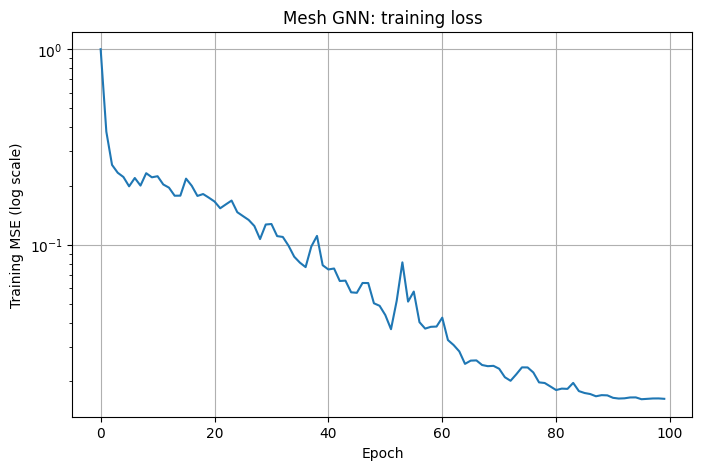

In [21]:
plt.figure(figsize=(8, 5))
plt.semilogy(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training MSE (log scale)")
plt.title("Mesh GNN: training loss")
plt.grid(True)
plt.show()

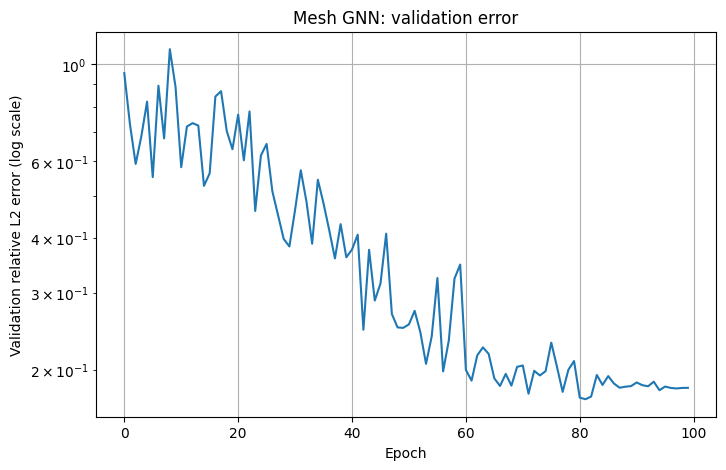

In [22]:
plt.figure(figsize=(8, 5))
plt.semilogy(history["val"])
plt.xlabel("Epoch")
plt.ylabel("Validation relative L2 error (log scale)")
plt.title("Mesh GNN: validation error")
plt.grid(True)
plt.show()

# Part VII — Test on unseen meshes

## 20. Same resolutions, new meshes

The test meshes have the same resolutions as training, but every mesh and every heat source is new.

In [23]:
err_same = relative_l2(model, test_same)
print(f"Edge-aware GNN, unseen meshes (n = 12, 16, 20): relative L2 error = {err_same:.4f}")

Edge-aware GNN, unseen meshes (n = 12, 16, 20): relative L2 error = 0.1265


## 21. Visualise one test prediction

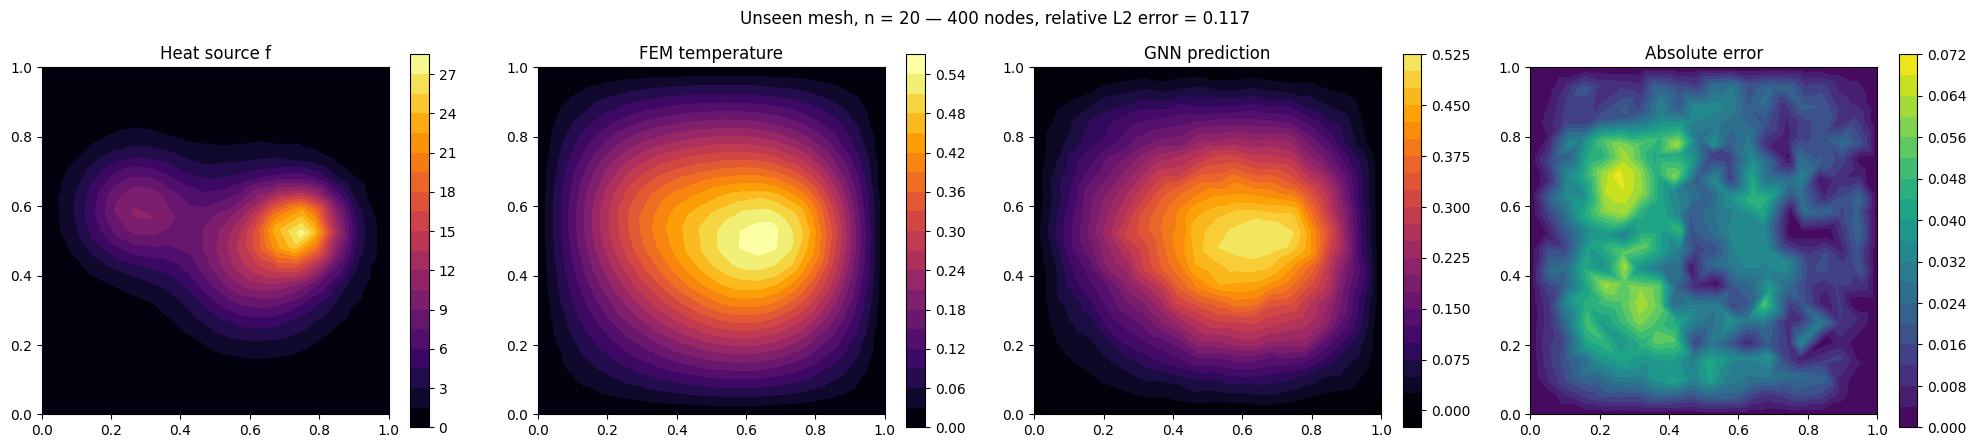

In [24]:
def plot_prediction(model, d, title):
    model.eval()
    with torch.no_grad():
        pred = model(d.to(device)).cpu().squeeze(-1) / T_SCALE
    true = d.y.cpu().squeeze(-1) / T_SCALE
    pos, tri = d.pos.cpu().numpy(), d.face.cpu().numpy().T

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    panels = [(d.x[:, 3].cpu() / F_SCALE, "Heat source f", "inferno"),
              (true, "FEM temperature", "inferno"),
              (pred, "GNN prediction", "inferno"),
              ((pred - true).abs(), "Absolute error", "viridis")]
    vmax = max(true.max(), pred.max()).item()
    for ax, (values, name, cmap) in zip(axes, panels):
        kwargs = {"vmin": 0, "vmax": vmax} if name in ("FEM temperature", "GNN prediction") else {}
        cf = ax.tricontourf(pos[:, 0], pos[:, 1], tri, values.numpy(), levels=20, cmap=cmap, **kwargs)
        fig.colorbar(cf, ax=ax)
        ax.set_title(name)
        ax.set_aspect("equal")
    rel = ((pred - true).norm() / true.norm()).item()
    fig.suptitle(f"{title} — {d.num_nodes} nodes, relative L2 error = {rel:.3f}")
    plt.tight_layout()
    plt.show()

plot_prediction(model, test_same[-1], "Unseen mesh, n = 20")

## 22. Compare with baselines

Is the mesh structure actually helping? We train two more models with the same data, schedule, and budget:

| Model | Uses connectivity? | Uses edge geometry? |
|---|---|---|
| Node MLP | ❌ | ❌ |
| GNN, no edge features | ✅ | ❌ |
| Edge-aware GNN | ✅ | ✅ |

In [25]:
models = {"Edge-aware GNN": model}

torch.manual_seed(7)
models["Node MLP"] = NodeMLP().to(device)
fit(models["Node MLP"], verbose=False)

torch.manual_seed(7)
models["GNN, no edge features"] = MeshGNN(num_layers=NUM_LAYERS, use_edge_attr=False).to(device)
fit(models["GNN, no edge features"], verbose=False)

print(f"{'Model':24s} | {'unseen meshes, n=12–20':>22s} | {'finer mesh, n=28':>16s}")
print("-" * 70)
results = {}
for name in ["Node MLP", "GNN, no edge features", "Edge-aware GNN"]:
    results[name] = (relative_l2(models[name], test_same), relative_l2(models[name], test_fine))
    print(f"{name:24s} | {results[name][0]:22.4f} | {results[name][1]:16.4f}")

Model                    | unseen meshes, n=12–20 | finer mesh, n=28
----------------------------------------------------------------------
Node MLP                 |                 0.5174 |           0.6834
GNN, no edge features    |                 0.2240 |           0.3829
Edge-aware GNN           |                 0.1265 |           0.3482


Read the table column by column.

**Unseen meshes at familiar resolutions.** The MLP sees only the source at each node, not where the heat goes. It cannot know how heat from a neighbouring heater spreads, so its error is large. Message passing lets each node collect information from its surroundings, which reduces the error a lot. Edge geometry tells the model how far apart neighbours are on an irregular mesh, and helps further.

**The finer mesh.** This is the honest test of a mesh surrogate. Look at how much the error grows from the first column to the second, for each model. The next sections explain why.

## 23. One prediction on the finer mesh

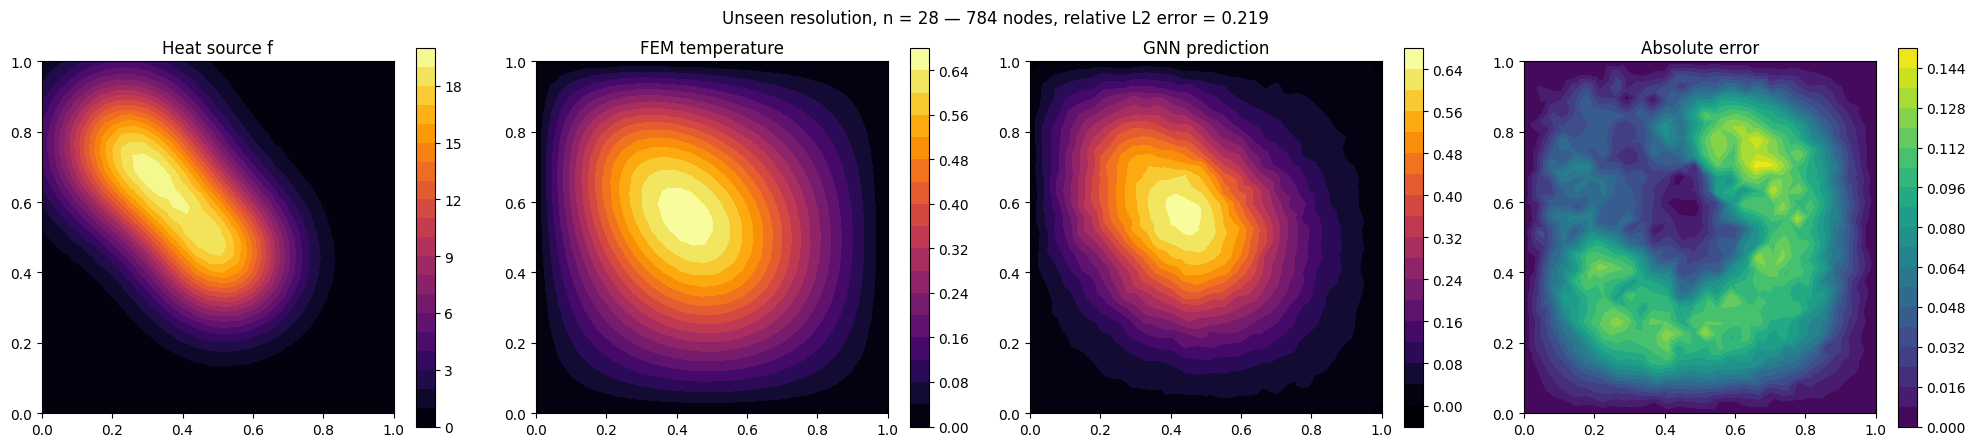

In [26]:
plot_prediction(model, test_fine[0], "Unseen resolution, n = 28")

# Part VIII — What happens inside a mesh GNN?

## 24. Receptive field vs. mesh resolution

Each processor layer moves information **one edge** further. After $L$ layers, a node knows about nodes at most $L$ hops away. On a mesh with spacing $h$, that is a physical distance of roughly

$$
\text{reach}\approx L\cdot h
$$

Our heat problem is **global**: the temperature at the centre depends on sources everywhere. Let's compare the model's reach with the size of the domain.

In [27]:
from torch_geometric.utils import k_hop_subgraph

print(f"Processor layers L = {NUM_LAYERS}")
print(f"{'n':>3s} | {'h':>6s} | {'reach L·h':>9s} | {'nodes within L hops of centre':>30s}")
print("-" * 58)
for n in [12, 16, 20, 28]:
    p, t, b = make_mesh(n, seed=0)
    ei = triangles_to_edge_index(t)
    centre = int(np.argmin(((p - 0.5) ** 2).sum(axis=1)))
    subset, _, _, _ = k_hop_subgraph(centre, NUM_LAYERS, ei, num_nodes=len(p))
    h = 1 / (n - 1)
    print(f"{n:3d} | {h:6.3f} | {NUM_LAYERS * h:9.2f} | {subset.numel():5d} of {len(p):4d} ({subset.numel() / len(p):.0%})")

Processor layers L = 8
  n |      h | reach L·h |  nodes within L hops of centre
----------------------------------------------------------
 12 |  0.091 |      0.73 |   144 of  144 (100%)
 16 |  0.067 |      0.53 |   228 of  256 (89%)
 20 |  0.053 |      0.42 |   262 of  400 (66%)
 28 |  0.037 |      0.30 |   245 of  784 (31%)


On the coarsest mesh, $L$ hops from the centre reach every node, so the centre "sees" every heater. As the mesh is refined, the same number of hops covers a smaller and smaller **physical** region: about two thirds of the nodes at $n=20$, and less than a third at $n=28$. A node near the centre of the fine mesh is blind to heat sources near the edges — which is exactly where the error on the fine mesh comes from.

This is a fundamental property of message passing on meshes:

> **A fixed number of layers corresponds to a fixed number of hops, not a fixed physical distance.** Refining the mesh shrinks the model's physical receptive field.

Remedies used in practice:

- **More layers** for finer meshes (expensive, and deep GNNs oversmooth — Tutorial 5).
- **Multi-scale / hierarchical meshes**: pass messages on a coarse mesh for long distances and on the fine mesh for detail (e.g. MultiScale MeshGraphNets, Fortunato et al., 2022). This connects to the hierarchical pooling of Tutorial 8.
- **Training on several resolutions**, so the model at least sees varied spacings — we did this with $n=12,16,20$.

## 25. Physical checks: boundary conditions

A small field error does not mean a prediction is physically valid. First check: the boundary condition $T=0$. The model only *learned* it from the boundary flag; nothing enforces it.

In [28]:
@torch.no_grad()
def boundary_error(model, dataset):
    model.eval()
    worst = 0.0
    for d in dataset:
        d = d.to(device)
        pred = model(d).squeeze(-1) / T_SCALE
        worst = max(worst, pred[d.boundary].abs().max().item())
    return worst

for name in ["Node MLP", "GNN, no edge features", "Edge-aware GNN"]:
    print(f"{name:24s} | max |T| on the boundary (should be 0): {boundary_error(models[name], test_same):.4f}")
print(f"\nFor scale: typical peak temperature = {np.mean([d.y.max().item() / T_SCALE for d in test_same]):.3f}")

Node MLP                 | max |T| on the boundary (should be 0): 0.0133
GNN, no edge features    | max |T| on the boundary (should be 0): 0.0048
Edge-aware GNN           | max |T| on the boundary (should be 0): 0.0013

For scale: typical peak temperature = 0.339


The boundary values are small but not zero. A simple fix is a **hard constraint**: multiply the output by $(1-b_i)$, so boundary predictions are exactly zero by construction. This is a common trick in physics-informed models — enforce what you know exactly instead of hoping the network learns it.

## 26. Physical checks: the PDE residual

The FEM solution satisfies $\mathbf K\mathbf T=\mathbf M\mathbf f$ exactly at interior nodes. For a prediction $\hat{\mathbf T}$, the **residual**

$$
\mathbf r=\mathbf K\hat{\mathbf T}-\mathbf M\mathbf f
$$

measures how far the prediction is from satisfying the discretised physics. We report it relative to $\lVert\mathbf M\mathbf f\rVert$.

In [29]:
@torch.no_grad()
def pde_residual(model, dataset):
    model.eval()
    res = []
    for d in dataset:
        pos, tri = d.pos.numpy().astype(np.float64), d.face.numpy().T
        K, m = assemble_fem(pos, tri)
        f = d.x[:, 3].numpy() / F_SCALE
        pred = model(d.to(device)).cpu().squeeze(-1).numpy() / T_SCALE
        interior = ~d.boundary.cpu().numpy()
        r = (K @ pred - m * f)[interior]
        res.append(np.linalg.norm(r) / np.linalg.norm((m * f)[interior]))
    return float(np.mean(res))

for name in ["Node MLP", "GNN, no edge features", "Edge-aware GNN"]:
    print(f"{name:24s} | relative PDE residual: {pde_residual(models[name], test_same):.3f}")

Node MLP                 | relative PDE residual: 2.016
GNN, no edge features    | relative PDE residual: 1.478
Edge-aware GNN           | relative PDE residual: 1.537


The residual is much larger than the field error — and it is **above 1** for every model. Since $\hat{\mathbf T}=\mathbf 0$ gives a relative residual of exactly 1, these predictions satisfy the discrete heat balance *worse than a field of zeros*, even though their temperature fields are visibly close to the truth.

This is typical: $\mathbf K$ is a discrete **second derivative**, and differentiating amplifies small, high-frequency wiggles in the prediction. A field that *looks* right can still badly violate the local energy balance. Field error and physical consistency are different questions, and a surrogate should be checked on both.

This is the gap between a **data-driven surrogate** and a **physically consistent** one. Ways to narrow it — adding the residual to the loss, conservative message functions, hard constraints — are the subject of Tutorial 10.

# 🧪 Hands-on Exercise 3 — Depth vs. resolution

Train models with $L = 4, 8, 12$ processor layers. Record the error on `test_same` and `test_fine`.

Does adding layers help more on the fine mesh than on the coarse ones? Relate your answer to the reach table in Section 24.

In [30]:
# TODO: vary the number of processor layers.

# for L in [4, 8, 12]:
#     torch.manual_seed(7)
#     m = MeshGNN(num_layers=L).to(device)
#     fit(m, verbose=False)
#     print(L, relative_l2(m, test_same), relative_l2(m, test_fine))

# 🧪 Hands-on Exercise 4 — Hard boundary condition

Modify `MeshGNN.forward` to return `self.decoder(h) * (1 - data.x[:, 2:3])`. Retrain and check:

1. Is the boundary error now exactly zero?
2. Does the interior error change?

In [31]:
# TODO: enforce T = 0 on the boundary by construction.

# class MeshGNNHardBC(MeshGNN):
#     def forward(self, data):
#         return super().forward(data) * (1 - data.x[:, 2:3])

# 🧪 Hands-on Exercise 5 — Train on the fine mesh too

Add 40 simulations with $n=28$ to the training set (new seeds!) and retrain. Evaluate on a **new** set of $n=28$ meshes and on a resolution you still have not trained on, e.g. $n=36$.

What does this tell you about how to build training sets for mesh surrogates?

In [32]:
# TODO: extend the training resolutions.

# 🧪 Hands-on Exercise 6 — Which edge features matter?

Train the edge-aware GNN with only $d_{ji}$, only $(\Delta x, \Delta y)$, and all three. Which carries the most useful information? Why might direction matter less for an isotropic problem like heat conduction?

In [33]:
# TODO: ablate edge features by slicing data.edge_attr.

# 🧪 Hands-on Exercise 7 — Physics-informed loss

Add the PDE residual from Section 26 to the training loss:

$$
\mathcal L=\text{MSE}(\hat{\mathbf T},\mathbf T)+\lambda\,\frac{\lVert\mathbf K\hat{\mathbf T}-\mathbf M\mathbf f\rVert^2}{\lVert\mathbf M\mathbf f\rVert^2}
$$

Store $\mathbf K$ as a sparse PyTorch tensor for each mesh. How does the residual change? Does the field error get better or worse?

In [34]:
# TODO: implement a residual-augmented loss.

# Part IX — From this notebook to real simulation data

## 27. Mapping OpenFOAM data to graphs

For a finite-volume code like OpenFOAM, the natural graph is the **cell graph**:

| OpenFOAM quantity | Graph data |
|---|---|
| Cell centres `C` | `pos`, node features |
| Internal faces (`owner`, `neighbour`) | `edge_index` (both directions) |
| Face area vectors `Sf` | edge features: area and normal |
| Cell-centre displacement across each face | edge features: $\Delta\mathbf r$, $d$ |
| Cell volumes `V` | node feature; weights for integral readouts (Tutorial 8) |
| `p`, `U`, `T` | node features or targets |
| Boundary patches | boundary flags or one-hot patch type on nodes; boundary faces as extra edge type |

Connecting cell centres alone does **not** reproduce the finite-volume operator: fluxes live on faces and depend on face area, normal, and interpolation. Face information must enter through edge features, or the model will have to guess it.

## 28. A practical pipeline

1. Export cell centres, face connectivity, face area vectors, and fields for each case.
2. Build one graph per **simulation case** (and per time step, for transient problems).
3. Normalise inputs and targets with **fixed** scales or training-set statistics — never per-case.
4. Split train/validation/test **by case**, and keep at least one test set at a **resolution or geometry** not seen in training.
5. Train an encode–process–decode GNN with geometric edge features.
6. Evaluate field errors, integrated quantities (Tutorial 8 readouts), boundary errors, and physical residuals.

## 29. Limitations to keep in mind

1. **Receptive field:** message passing is local; global problems need enough layers or multi-scale meshes.
2. **No conservation guarantee:** mean aggregation and MLP updates do not conserve mass, momentum, or energy by construction.
3. **Soft boundary conditions:** unless enforced, BCs are only approximately learned.
4. **Resolution transfer is not free:** a model trained on coarse meshes can lose accuracy on fine ones.
5. **Synthetic data:** our solver is simple and our sources are Gaussian blobs; real geometries and physics are harder.

# 🚀 Final Challenge — A heat-conduction surrogate that transfers

Extend the experiment into a small study:

1. Add **geometry variation**: a plate with a circular hole of random radius (remove triangles inside the hole and mark the hole edge as boundary).
2. Add an **operating parameter**: a spatially uniform conductivity $k$, as a node feature, with $-\nabla\cdot(k\nabla T)=f$.
3. Train on $n\in\{12,16,20\}$ and test on unseen geometries at $n=20$ and $n=28$.

| Model | Unseen geometry, $n=20$ | Unseen geometry, $n=28$ | Boundary error | PDE residual |
|---|---:|---:|---:|---:|
| Node MLP | ? | ? | ? | ? |
| GNN, no edge features | ? | ? | ? | ? |
| Edge-aware GNN | ? | ? | ? | ? |
| Edge-aware GNN + hard BC | ? | ? | ? | ? |

**Research question:** which design choices — edge features, depth, hard constraints, multi-resolution training — matter most for transfer to new meshes and geometries?

### Completion checklist

- [ ] I can map vertices, cells, and faces of a mesh to nodes, edges, and features.
- [ ] I converted triangles to `edge_index` and verified it with `FaceToEdge` and Euler's formula.
- [ ] I built and verified a small FEM solver as a data generator.
- [ ] I created a dataset split **by simulation case**, with an unseen-resolution test set.
- [ ] I trained an encode–process–decode GNN and compared it with an MLP and a GNN without edge features.
- [ ] I can explain why a fixed number of layers covers less physical distance on a finer mesh.
- [ ] I checked boundary errors and the PDE residual, and can explain why they matter.

# 30. Summary

We learned:
- how a mesh maps to a graph, and why the choice of vertex, cell, or face graph depends on the numerical method
- how to convert triangles to `edge_index`, and that the FEM stiffness matrix has exactly the same sparsity pattern
- how to build node features (coordinates, boundary flag, source) and geometric edge features (relative position, distance)
- how to generate surrogate training data with a verified finite-element solver
- how to build an encode–process–decode GNN with edge-aware message passing
- that connectivity and edge geometry both reduce the error on unseen meshes
- that a fixed number of message-passing layers covers less physical distance as the mesh is refined
- that low field error does not imply low PDE residual or exact boundary conditions

The key takeaway:

> A mesh is a graph with geometry. Give the GNN that geometry through edge features, evaluate it on **unseen meshes and resolutions**, and check the physics — not just the error.

# 31. What comes next?

## Tutorial 10 — GNNs for Scientific Machine Learning

We now have a working mesh surrogate and a clear list of its weaknesses. In the final tutorial, we bring the series together and look at how GNNs are used — and improved — as scientific models:

```text
data-driven surrogate (this tutorial)
    ↓
physics-informed losses and hard constraints
    ↓
conservative and symmetry-aware message passing
    ↓
time-stepping surrogates and rollout stability
    ↓
multi-scale meshes and generalisation across geometries
```

---

## References and further reading

1. Pfaff, T. et al. (2021). [Learning Mesh-Based Simulation with Graph Networks](https://arxiv.org/abs/2010.03409). ICLR.
2. Sanchez-Gonzalez, A. et al. (2020). [Learning to Simulate Complex Physics with Graph Networks](https://arxiv.org/abs/2002.09405). ICML.
3. Brandstetter, J., Worrall, D., and Welling, M. (2022). [Message Passing Neural PDE Solvers](https://arxiv.org/abs/2202.03376). ICLR.
4. Fortunato, M. et al. (2022). [MultiScale MeshGraphNets](https://arxiv.org/abs/2210.00612). ICML AI4Science Workshop.
5. Gilmer, J. et al. (2017). [Neural Message Passing for Quantum Chemistry](https://proceedings.mlr.press/v70/gilmer17a.html). ICML.

- [DeepMind MeshGraphNets code](https://github.com/google-deepmind/deepmind-research/tree/master/meshgraphnets)
- [PyTorch Geometric](https://github.com/pyg-team/pytorch_geometric) · [`MessagePassing`](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.conv.MessagePassing.html) · [`FaceToEdge`](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.transforms.FaceToEdge.html)
- [NVIDIA PhysicsNeMo](https://github.com/NVIDIA/physicsnemo)

---

**Learn the graph. Understand the message passing. Build the model. Connect it to the physical world.**

*HalfQubiX · The Learning Stack*